# Stage 6: Meals and Glucose Spikes (Participant 001)

This stage links the glucose curve to what was eaten. We find the spikes, match them to meals, and measure each meal's glucose response.

| # | Question |
|---|---|
| Q1 | When do spikes occur, and how many are there? |
| Q2 | Does each spike line up with a logged meal? Are there spikes with **no** meal logged? |
| Q3 | For each meal: what is the baseline, the peak, and the time to peak? |
| Q4 | How long does glucose take to return to baseline after a meal? |
| Q5 | Do meals with more carbs or sugar produce bigger spikes? |
| Q6 | Do fiber, protein, or fat seem to reduce the spike size? |
| Q7 | How consistent is the response to the **standardized breakfast** across days? |
| Q8 | Do breakfast, lunch, and dinner produce different responses? |
| Q9 | *(added)* Does glucose dip below baseline after a spike (reactive low)? |
| Q10 | *(added)* Does the pre-meal glucose level affect the spike size? |
| Q11 | *(added)* Do liquid meals (smoothies, drinks) spike more than solid meals? |
| Q12 | *(added)* Which meals caused the biggest responses? |

## Setup

| Setting | Value | Meaning |
|---|---|---|
| `SPIKE_THR` | 140 | Absolute spike threshold (mg/dL) |
| `PEAK_PROMINENCE` | 20 | A *relative* spike must stand at least 20 mg/dL above its surroundings |
| `MERGE_MIN` | 30 | Food items logged within 30 min of each other count as one meal |
| `BASELINE_MIN` | 30 | Baseline = median glucose in the 30 min before the meal |
| `PEAK_WINDOW_MIN` | 120 | Look for the peak in the 2 h after the meal |
| `RECOVERY_TOL` | 10 | "Back to baseline" = within 10 mg/dL of the baseline |
| `MIN_RISE` | 10 | A rise below 10 mg/dL counts as "no clear response"; time to peak and recovery are left empty for those meals |
| `OVERLAP_MIN` | 120 | If another meal follows within 2 h, the response is marked as overlapped |

People without diabetes rarely go above 140 mg/dL, so we detect spikes in two ways: **absolute** (above 140) and **relative** (a clear rise above the surrounding level, whatever the absolute value).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings("ignore", message="obj.round has no effect")   # rounding tables that contain dates

PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
RAW_PATH = f"{DATA_DIR}/{PID}/Dexcom_{PID}.csv"
FOOD_PATH = f"{DATA_DIR}/{PID}/Food_Log_{PID}.csv"
MEALS_PATH = f"../clean_data/meals_{PID}.csv"

SPIKE_THR = 140
PEAK_PROMINENCE = 20
MERGE_MIN = 30
BASELINE_MIN = 30
PEAK_WINDOW_MIN = 120
RESPONSE_WINDOW_MIN = 180
RECOVERY_TOL = 10
MIN_RISE = 10            # a rise smaller than this counts as "no clear response"
OVERLAP_MIN = 120
INTERVAL = pd.Timedelta("5min")

TIME_FIXES = {"2020-02-18 01:40:00": "2020-02-18 13:40:00"}   # from Stage 4

## Load glucose

We put the readings on a regular 5-minute grid (as in Stage 3), so windows like "2 hours after the meal" always contain the expected number of slots, and gaps show up as `NaN`.

In [2]:
if os.path.exists(CLEAN_PATH):
    glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"])
else:
    raw = pd.read_csv(RAW_PATH, skiprows=range(1, 13))
    raw = raw[raw["Event Type"] == "EGV"]
    glu = pd.DataFrame({
        "timestamp": pd.to_datetime(raw["Timestamp (YYYY-MM-DDThh:mm:ss)"]),
        "glucose": pd.to_numeric(raw["Glucose Value (mg/dL)"], errors="coerce"),
    }).dropna().drop_duplicates("timestamp")
glu = glu.sort_values("timestamp").reset_index(drop=True)

start = glu["timestamp"].iloc[0]
slot = ((glu["timestamp"] - start) / INTERVAL).round().astype(int)
grid = glu.assign(slot=slot).drop_duplicates("slot").set_index("slot")["glucose"].reindex(range(slot.max() + 1))
grid.index = start + grid.index * INTERVAL
grid.index.name = "timestamp"
print("Grid slots:", len(grid), "| missing:", int(grid.isna().sum()))

Grid slots: 2599 | missing: 38


## Load the food log and build meals

Unlike Stage 4, here we keep **all nutrients** (fiber, protein, fat too), because Q6 needs them. Steps:
1. apply the Feb 18 time fix from Stage 4
2. merge items logged within `MERGE_MIN` minutes into one meal (e.g. a salad at 12:30 and a hot chocolate at 13:00 overlap in their glucose effect anyway)
3. flag the standard breakfast and **liquid** items (smoothies, hot chocolate, Boost, and anything measured in fluid ounces)
4. label each meal as breakfast, lunch, dinner, or snack

In [3]:
food = pd.read_csv(FOOD_PATH)
food["time_begin"] = pd.to_datetime(food["time_begin"])
for old, new in TIME_FIXES.items():
    food.loc[food["time_begin"] == pd.Timestamp(old), "time_begin"] = pd.Timestamp(new)
food = food.sort_values("time_begin").reset_index(drop=True)

# Liquid items: measured in fluid ounces, or obviously a drink
name = food["logged_food"].astype(str).str.lower()
food["liquid"] = (food["unit"].astype(str).str.contains("fluid", case=False)
                  | name.str.contains("smoothie|boost|hot chocolate|juice|shake|latte|soda"))
# Milk poured on cereal is part of a solid meal, so it doesn't count as a drink
food.loc[name.str.contains("lactose free|milk") & ~name.str.contains("shake|smoothie"), "liquid"] = False
food["liquid_carbs"] = food["total_carb"].where(food["liquid"], 0)

# Merge items into meals
meal_id, current_start, ids = 0, None, []
for t in food["time_begin"]:
    if current_start is None or t - current_start > pd.Timedelta(minutes=MERGE_MIN):
        meal_id += 1
        current_start = t
    ids.append(meal_id)
food["meal_id"] = ids

nsum = lambda x: x.sum(min_count=1)   # keep NaN if every item is missing that nutrient
meals = food.groupby("meal_id").agg(
    time=("time_begin", "min"),
    foods=("logged_food", lambda x: ", ".join(x.astype(str))),
    items=("logged_food", "size"),
    calories=("calorie", nsum),
    carbs=("total_carb", nsum),
    sugar=("sugar", nsum),
    fiber=("dietary_fiber", nsum),
    protein=("protein", nsum),
    fat=("total_fat", nsum),
    liquid_carbs=("liquid_carbs", "sum"),
    standard=("logged_food", lambda x: x.astype(str).str.contains("Standard Breakfast", case=False).any()),
).reset_index(drop=True)

meals["liquid"] = meals["liquid_carbs"] >= 0.5 * meals["carbs"].fillna(0)
meals.loc[meals["carbs"].fillna(0) == 0, "liquid"] = False

def meal_type(r):
    h = r["time"].hour + r["time"].minute / 60
    if r["standard"]:
        return "breakfast"
    if pd.isna(r["calories"]) or r["calories"] < 150:
        return "snack"
    if 4 <= h < 11:
        return "breakfast"
    if 11 <= h < 15.5:
        return "lunch"
    if 17 <= h < 23.5:
        return "dinner"
    return "snack"

meals["type"] = meals.apply(meal_type, axis=1)
meals["date"] = meals["time"].dt.date
print("Food items:", len(food), "→ meals:", len(meals))
print(meals["type"].value_counts().to_string())
meals[["time", "type", "foods", "carbs", "sugar", "protein", "fiber", "fat", "liquid", "standard"]]

Food items: 61 → meals: 38
type
lunch        12
dinner       10
breakfast    10
snack         6


,time,type,foods,carbs,sugar,protein,fiber,fat,liquid,standard
0,2020-02-13 18:00:00,dinner,Berry Smoothie,85.0,83.0,16.0,1.7,3.3,True,False
1,2020-02-13 20:30:00,dinner,"Chicken Leg, Asparagus",2.5,0.8,63.4,1.2,23.1,False,False
2,2020-02-14 07:10:00,breakfast,"Natrel Lactose Free 2 Percent, Standard Breakfast",35.0,18.0,13.0,NaN,NaN,False,True
3,2020-02-14 09:38:00,breakfast,Breakfast Trail Mix,30.0,22.0,4.0,NaN,NaN,False,False
4,2020-02-14 12:38:00,lunch,"Spinach Salad w/ strawberries and cheese, Egg",14.4,8.7,13.9,NaN,NaN,False,False
5,2020-02-14 19:30:00,dinner,"Acai Smoothie, (Trader Joe's) Mac and Cheese, ...",145.5,76.6,21.0,NaN,NaN,True,False
6,2020-02-15 07:30:00,breakfast,Spinach Smoothie,69.0,38.0,7.2,NaN,NaN,True,False
7,2020-02-15 11:02:00,lunch,Breakfast Trail Mix,30.0,22.0,4.0,NaN,NaN,False,False
8,2020-02-15 12:38:00,lunch,"Spinach Salad w/ blueberries, egg, and cheese,...",14.4,8.7,13.9,NaN,NaN,False,False
9,2020-02-15 15:30:00,snack,"Babel Cheese, Breakfast Trail Mix",30.3,22.3,9.0,NaN,NaN,False,False


In [4]:
# How complete is each nutrient in the log?
meals[["calories", "carbs", "sugar", "protein", "fiber", "fat"]].notna().mean().mul(100).round(0) \
    .to_frame("% of meals with a value").T

,calories,carbs,sugar,protein,fiber,fat
% of meals with a value,100.0,100.0,100.0,100.0,8.0,8.0


---
## Q1: When do spikes occur, and how many?

**Absolute spikes:** continuous periods with glucose ≥ 140 mg/dL.

**Relative spikes:** peaks that stand at least `PEAK_PROMINENCE` mg/dL above the surrounding curve (found with `scipy.signal.find_peaks`). This catches meal responses that stay below 140, which is common in people without diabetes. For each peak we also record the **rise** from the lowest point in the 2 hours before it.

In [5]:
# Absolute spikes: runs of consecutive readings ≥ SPIKE_THR
above = grid >= SPIKE_THR
run = (above != above.shift()).cumsum()
abs_spikes = (
    grid[above].groupby(run[above])
    .agg(start=lambda s: s.index.min(), end=lambda s: s.index.max(), peak="max", readings="count")
    .reset_index(drop=True)
)
abs_spikes["duration_min"] = abs_spikes["readings"] * 5
print(f"Absolute spikes (≥ {SPIKE_THR} mg/dL): {len(abs_spikes)}")
abs_spikes

Absolute spikes (≥ 140 mg/dL): 22


,start,end,peak,readings,duration_min
0,2020-02-13 18:48:32,2020-02-13 18:53:32,143.0,2,10
1,2020-02-14 20:18:32,2020-02-14 20:28:32,143.0,3,15
2,2020-02-14 21:08:32,2020-02-14 21:23:32,141.0,4,20
3,2020-02-14 21:43:32,2020-02-14 22:03:32,146.0,5,25
4,2020-02-16 12:38:32,2020-02-16 12:38:32,140.0,1,5
5,2020-02-16 21:13:32,2020-02-16 21:23:32,142.0,3,15
6,2020-02-17 21:38:32,2020-02-17 21:38:32,140.0,1,5
7,2020-02-17 22:38:32,2020-02-17 23:43:32,152.0,14,70
8,2020-02-18 00:18:32,2020-02-18 00:33:32,141.0,4,20
9,2020-02-18 06:58:32,2020-02-18 07:03:32,141.0,2,10


In [6]:
# Relative spikes: prominent peaks (short gaps filled only for peak detection)
filled = grid.interpolate(limit_area="inside").dropna()
idx, props = find_peaks(filled.values, prominence=PEAK_PROMINENCE, distance=12)

peaks = pd.DataFrame({
    "time": filled.index[idx],
    "glucose": filled.values[idx],
    "prominence": props["prominences"],
})
peaks = peaks[grid.reindex(peaks["time"]).notna().values].reset_index(drop=True)   # drop peaks inside gaps
peaks["rise_2h"] = [p - filled[t - pd.Timedelta("2h"): t].min() for t, p in zip(peaks["time"], peaks["glucose"])]
peaks["hour"] = peaks["time"].dt.hour
peaks["above_140"] = peaks["glucose"] >= SPIKE_THR

print(f"Relative spikes (prominence ≥ {PEAK_PROMINENCE} mg/dL): {len(peaks)}")
print(f"  of which also ≥ {SPIKE_THR}: {int(peaks['above_140'].sum())}")
print(f"Spikes per day: {len(peaks) / grid.index.normalize().nunique():.1f}")
peaks.round(1)

Relative spikes (prominence ≥ 20 mg/dL): 44
  of which also ≥ 140: 16
Spikes per day: 4.4


,time,glucose,prominence,rise_2h,hour,above_140
0,2020-02-13 18:48:32,143.0,77.0,85.0,18,True
1,2020-02-13 23:43:32,114.0,32.0,29.0,23,False
2,2020-02-14 08:18:32,122.0,39.0,33.0,8,False
3,2020-02-14 10:33:32,110.0,22.0,27.0,10,False
4,2020-02-14 13:13:32,124.0,40.0,36.0,13,False
5,2020-02-14 21:53:32,146.0,88.0,37.0,21,True
6,2020-02-15 11:58:32,105.0,34.0,17.0,11,False
7,2020-02-15 16:23:32,122.0,43.0,51.0,16,False
8,2020-02-15 20:53:32,112.0,23.0,32.0,20,False
9,2020-02-15 22:03:32,114.0,27.0,26.0,22,False


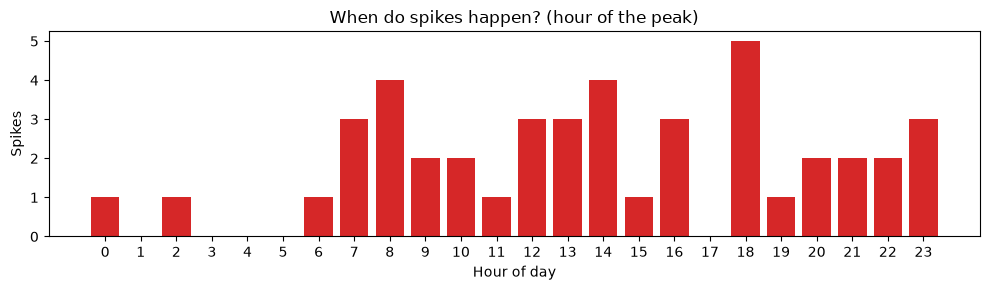

In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(24), peaks.groupby("hour").size().reindex(range(24), fill_value=0), color="tab:red")
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Spikes")
ax.set_title("When do spikes happen? (hour of the peak)")
plt.tight_layout()
plt.show()

---
## Q2: Does each spike line up with a meal?

A meal is linked to a spike if it was logged between **150 minutes and 5 minutes before the peak**. Glucose usually peaks 30–90 minutes after eating, and logged times are often a little off, so the window is generous.

Spikes with no meal in that window may come from unlogged food, stress, the dawn phenomenon, or the rebound after a sensor dip.

In [8]:
def meals_before(t, lo=150, hi=5):
    m = meals[(meals["time"] >= t - pd.Timedelta(minutes=lo)) & (meals["time"] <= t - pd.Timedelta(minutes=hi))]
    return m

linked = []
for t in peaks["time"]:
    m = meals_before(t)
    linked.append({
        "linked_meal_time": m["time"].max() if len(m) else pd.NaT,
        "linked_foods": "; ".join(m["foods"].str[:40]) if len(m) else "",
        "minutes_after_meal": (t - m["time"].max()).total_seconds() / 60 if len(m) else np.nan,
    })
peaks = pd.concat([peaks, pd.DataFrame(linked)], axis=1)
peaks["meal_linked"] = peaks["linked_meal_time"].notna()

n_link = int(peaks["meal_linked"].sum())
print(f"Spikes linked to a meal: {n_link} of {len(peaks)}")
print(f"Spikes with NO meal logged: {len(peaks) - n_link}")
print(f"Median time from meal to peak: {peaks['minutes_after_meal'].median():.0f} min")

Spikes linked to a meal: 31 of 44
Spikes with NO meal logged: 13
Median time from meal to peak: 54 min


In [9]:
print("Spikes without a logged meal:")
peaks.loc[~peaks["meal_linked"], ["time", "glucose", "prominence", "rise_2h", "hour"]].round(1)

Spikes without a logged meal:


,time,glucose,prominence,rise_2h,hour
1,2020-02-13 23:43:32,114.0,32.0,29.0,23
19,2020-02-18 09:08:32,111.0,20.0,37.0,9
20,2020-02-18 10:53:32,118.0,24.0,27.0,10
23,2020-02-18 18:48:32,130.0,27.0,26.0,18
24,2020-02-19 00:38:32,126.0,22.0,22.0,0
25,2020-02-19 02:43:32,126.0,22.0,8.0,2
27,2020-02-19 14:43:32,138.0,31.0,31.0,14
34,2020-02-20 18:43:32,124.0,21.0,29.0,18
36,2020-02-20 23:03:32,148.0,61.0,23.0,23
40,2020-02-21 16:23:32,137.0,36.0,48.0,16


In [10]:
# The other direction: meals that were NOT followed by a spike
meal_has_spike = [((peaks["time"] > t + pd.Timedelta("5min")) & (peaks["time"] <= t + pd.Timedelta("150min"))).any()
                  for t in meals["time"]]
meals["followed_by_spike"] = meal_has_spike
print(f"Meals followed by a spike: {sum(meal_has_spike)} of {len(meals)}")
meals.loc[~meals["followed_by_spike"], ["time", "type", "foods", "carbs"]]

Meals followed by a spike: 31 of 38


,time,type,foods,carbs
1,2020-02-13 20:30:00,dinner,"Chicken Leg, Asparagus",2.5
6,2020-02-15 07:30:00,breakfast,Spinach Smoothie,69.0
8,2020-02-15 12:38:00,lunch,"Spinach Salad w/ blueberries, egg, and cheese,...",14.4
24,2020-02-18 22:00:00,dinner,Ranch Wings,30.4
28,2020-02-19 20:00:00,dinner,Chicken and Rice,22.0
36,2020-02-21 19:50:00,dinner,"Cheese Pita, Spinach Smoothie",164.0
37,2020-02-22 15:10:00,lunch,Boost,82.0


### Every day at a glance

One row per day: the glucose curve, logged meals (green lines, labelled with carbs), and spikes (red = linked to a meal, black = no meal logged).

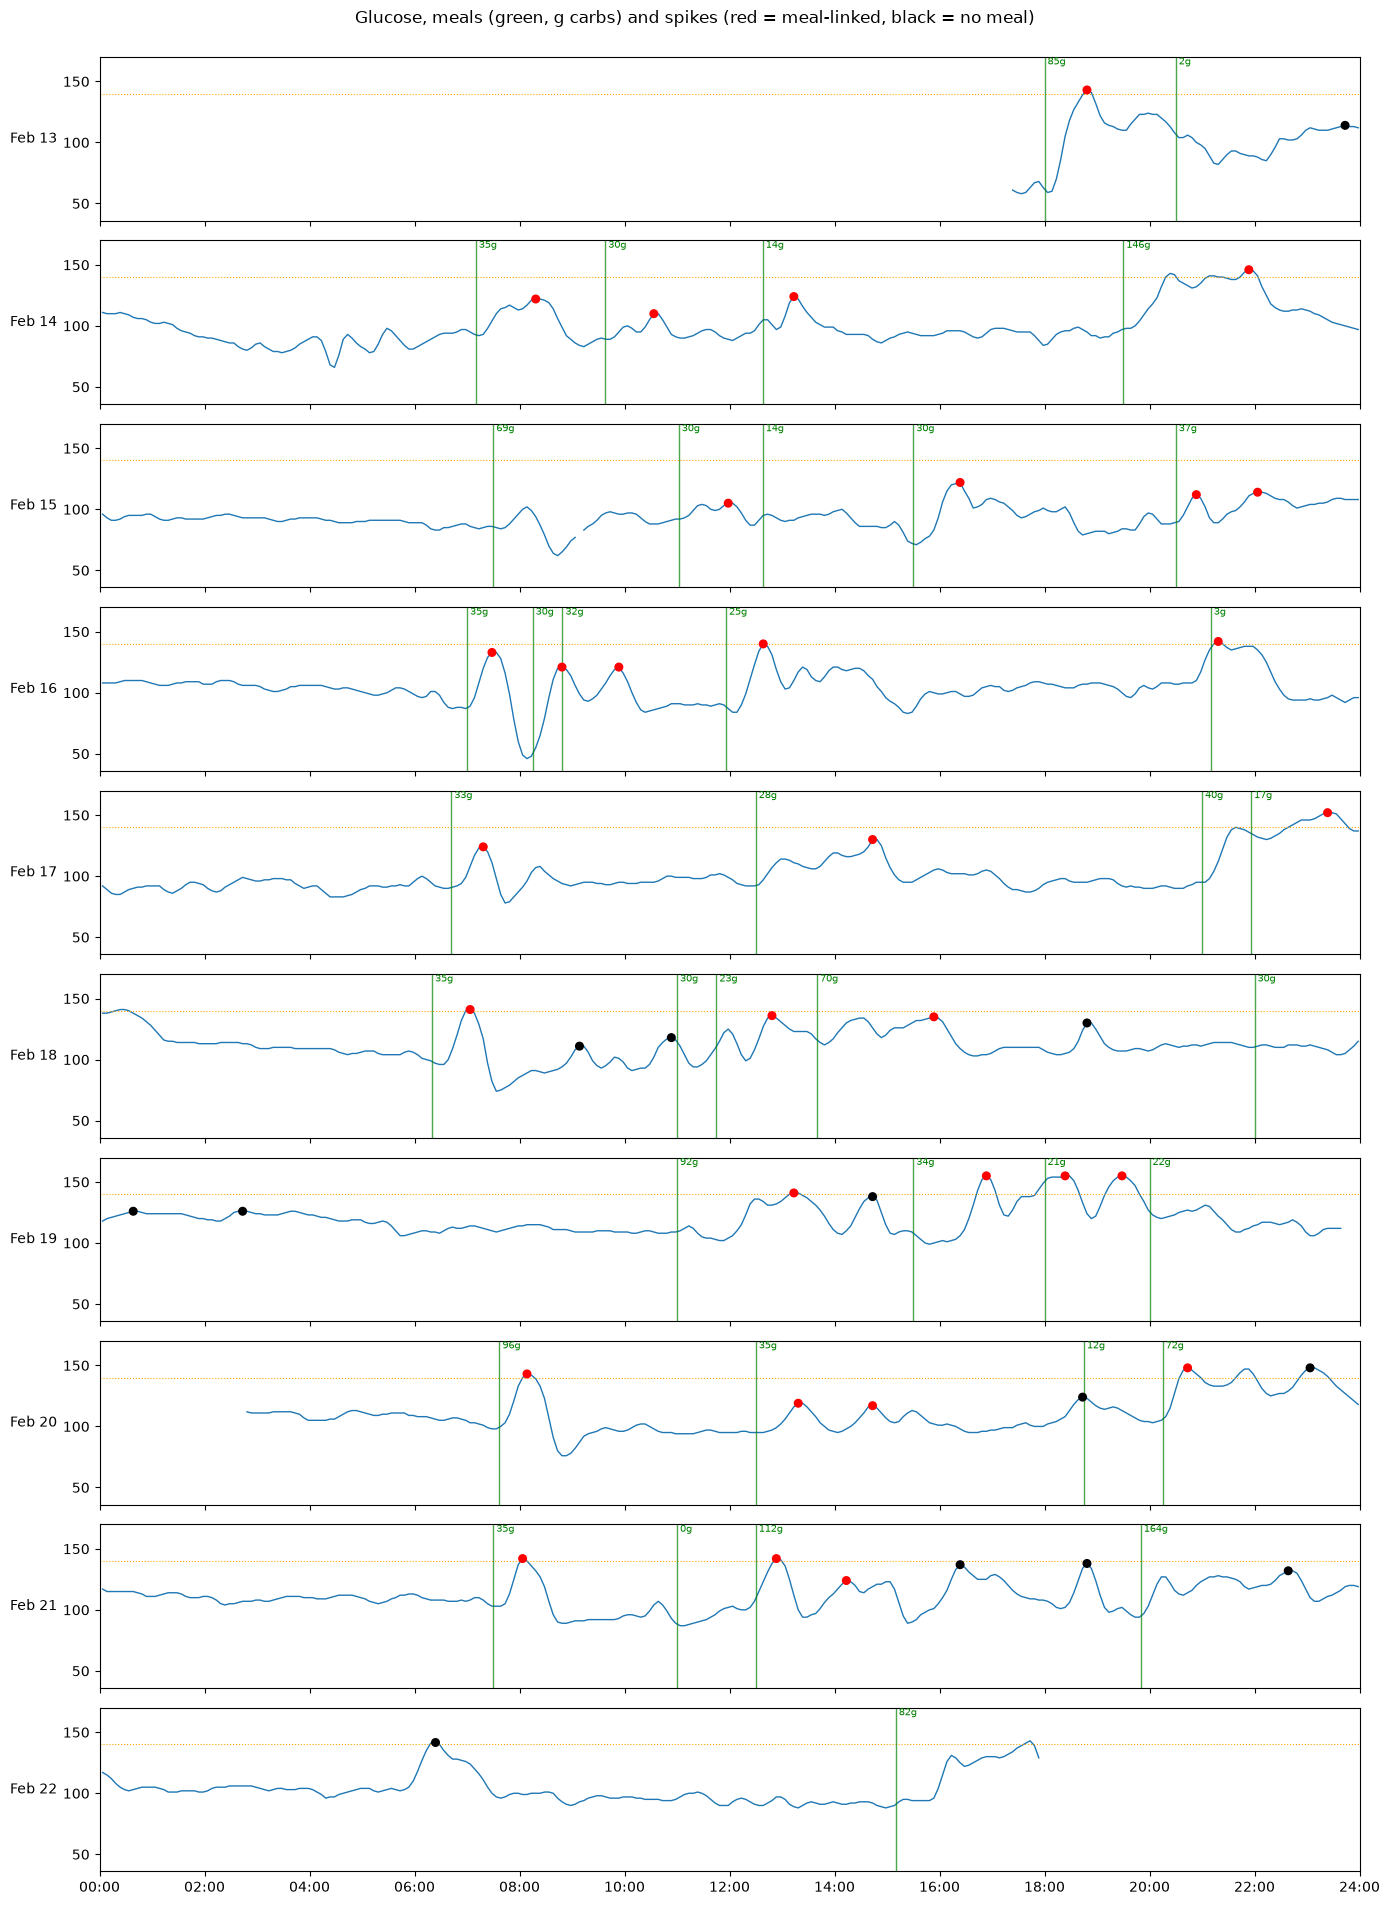

In [11]:
days = sorted(grid.index.normalize().unique())
fig, axes = plt.subplots(len(days), 1, figsize=(14, 1.9 * len(days)), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
ybot, ytop = grid.min() - 10, grid.max() + 15

for ax, d in zip(axes, days):
    g = grid[d: d + pd.Timedelta("24h")]
    hrs = (g.index - d).total_seconds() / 3600
    ax.plot(hrs, g.values, color="tab:blue", lw=1)
    ax.axhline(SPIKE_THR, color="orange", ls=":", lw=0.8)

    for _, m in meals[meals["time"].dt.normalize() == d].iterrows():
        h = (m["time"] - d).total_seconds() / 3600
        ax.axvline(h, color="green", lw=1, alpha=0.7)
        ax.text(h, ytop, f" {m['carbs']:.0f}g", fontsize=7, color="green", va="top")

    p = peaks[peaks["time"].dt.normalize() == d]
    ph = (p["time"] - d).dt.total_seconds() / 3600
    ax.scatter(ph, p["glucose"], c=np.where(p["meal_linked"], "red", "black"), s=30, zorder=3)
    ax.set_ylabel(f"{d:%b %d}", rotation=0, ha="right", va="center")

axes[-1].set_xlim(0, 24)
axes[-1].set_ylim(ybot, ytop)
axes[-1].set_xticks(range(0, 25, 2))
axes[-1].set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)])
fig.suptitle("Glucose, meals (green, g carbs) and spikes (red = meal-linked, black = no meal)", y=1.0)
plt.tight_layout()
plt.show()

---
## Q3: Baseline, peak, and time to peak for each meal

For every meal we measure:

| Metric | Definition |
|---|---|
| baseline | median glucose in the 30 min before the meal |
| peak | highest glucose in the 2 h after the meal |
| rise | peak − baseline (the spike size) |
| time to peak | minutes from the logged meal time to the peak |
| iAUC | *incremental area under the curve*: area between the curve and the baseline over 0–2 h, counting only the part above baseline. It captures both height and duration. |

Responses are only clean when nothing else was eaten nearby, so each meal is flagged:
- **overlapped:** another meal followed within 2 h
- **prev_meal_close:** a meal was eaten in the 90 min before, so the baseline isn't a true resting level
- **rising_before_log:** glucose was already rising at the logged time, so the log time is probably late

In [12]:
def trapezoid(y, dx=5):
    y = np.asarray(y, dtype=float)
    return float(np.sum((y[1:] + y[:-1]) / 2 * dx)) if len(y) > 1 else np.nan

def meal_response(t):
    pre = grid[t - pd.Timedelta(minutes=BASELINE_MIN): t - pd.Timedelta("1s")]
    peak_win = grid[t: t + pd.Timedelta(minutes=PEAK_WINDOW_MIN)]
    resp_win = grid[t: t + pd.Timedelta(minutes=RESPONSE_WINDOW_MIN)]

    expected = PEAK_WINDOW_MIN // 5
    if pre.count() < 3 or peak_win.count() < 0.8 * expected:
        return {"valid": False}

    baseline = pre.median()
    peak = peak_win.max()
    t_peak = peak_win.idxmax()

    excess = (peak_win - baseline).clip(lower=0).interpolate(limit_area="inside").fillna(0)
    iauc = trapezoid(excess.values)

    after_peak = grid[t_peak: t + pd.Timedelta("4h")]
    back = after_peak[after_peak <= baseline + RECOVERY_TOL]
    recovery = (back.index[0] - t).total_seconds() / 60 if len(back) else np.nan

    post_peak = resp_win[t_peak:]
    nadir = post_peak.min() if post_peak.count() else np.nan

    at_log = grid[t - pd.Timedelta("5min"): t + pd.Timedelta("5min")].mean()
    responded = (peak - baseline) >= MIN_RISE
    return {
        "valid": True,
        "baseline": baseline,
        "peak": peak,
        "rise": peak - baseline,
        "responded": responded,
        # timing only makes sense when there was a real rise
        "time_to_peak_min": (t_peak - t).total_seconds() / 60 if responded else np.nan,
        "iAUC_2h": iauc,
        "recovery_min": recovery if responded else np.nan,
        "nadir_after": nadir,
        "dip_below_baseline": nadir - baseline,
        "rising_before_log": (at_log - pre.min()) > 15,
    }

resp = pd.DataFrame([meal_response(t) for t in meals["time"]])
mr = pd.concat([meals.reset_index(drop=True), resp], axis=1)

next_gap = (mr["time"].shift(-1) - mr["time"]).dt.total_seconds() / 60
prev_gap = (mr["time"] - mr["time"].shift(1)).dt.total_seconds() / 60
mr["overlapped"] = next_gap < OVERLAP_MIN
mr["prev_meal_close"] = prev_gap < 90
mr["clean"] = mr["valid"] & ~mr["overlapped"] & ~mr["prev_meal_close"]
mr["rise_per_10g_carb"] = np.where(mr["carbs"] >= 10, mr["rise"] / mr["carbs"] * 10, np.nan)

print(f"Meals with a measurable response: {int(mr['valid'].sum())} of {len(mr)}")
print(f"Meals with a clear rise (≥ {MIN_RISE}): {int(mr['responded'].fillna(False).sum())}")
print(f"Clean responses (no overlap):     {int(mr['clean'].sum())}")

cols = ["time", "type", "foods", "carbs", "baseline", "peak", "rise", "responded", "time_to_peak_min",
        "iAUC_2h", "recovery_min", "overlapped", "prev_meal_close", "rising_before_log"]
mr.loc[mr["valid"], cols].assign(foods=lambda d: d["foods"].str[:35]).round(1)

Meals with a measurable response: 38 of 38
Meals with a clear rise (≥ 10): 34
Clean responses (no overlap):     28


,time,type,foods,carbs,baseline,peak,rise,responded,time_to_peak_min,iAUC_2h,recovery_min,overlapped,prev_meal_close,rising_before_log
0,2020-02-13 18:00:00,dinner,Berry Smoothie,85.0,63.0,143.0,80.0,True,48.5,5887.5,NaN,False,False,False
1,2020-02-13 20:30:00,dinner,"Chicken Leg, Asparagus",2.5,118.5,106.0,-12.5,False,NaN,0.0,NaN,False,False,False
2,2020-02-14 07:10:00,breakfast,"Natrel Lactose Free 2 Percent, Stan",35.0,95.0,122.0,27.0,True,68.5,1655.0,98.5,False,False,False
3,2020-02-14 09:38:00,breakfast,Breakfast Trail Mix,30.0,86.0,110.0,24.0,True,55.5,1210.0,75.5,False,False,False
4,2020-02-14 12:38:00,lunch,Spinach Salad w/ strawberries and c,14.4,94.0,124.0,30.0,True,35.5,1072.5,60.5,False,False,False
5,2020-02-14 19:30:00,dinner,"Acai Smoothie, (Trader Joe's) Mac a",145.5,92.5,143.0,50.5,True,53.5,4090.0,NaN,False,False,False
6,2020-02-15 07:30:00,breakfast,Spinach Smoothie,69.0,85.5,102.0,16.5,True,38.5,398.8,48.5,False,False,False
7,2020-02-15 11:02:00,lunch,Breakfast Trail Mix,30.0,89.5,105.0,15.5,True,56.5,905.0,71.5,True,False,False
8,2020-02-15 12:38:00,lunch,"Spinach Salad w/ blueberries, egg,",14.4,91.0,100.0,9.0,False,NaN,390.0,NaN,False,False,False
9,2020-02-15 15:30:00,snack,"Babel Cheese, Breakfast Trail Mix",30.3,84.0,122.0,38.0,True,53.5,2192.5,123.5,False,False,False


In [13]:
v = mr[mr["valid"]]
c = mr[mr["clean"]]
print("All valid meals:")
print(f"  median rise:          {v['rise'].median():.0f} mg/dL")
print(f"  median time to peak:  {v['time_to_peak_min'].median():.0f} min")
print("Clean meals only:")
print(f"  median rise:          {c['rise'].median():.0f} mg/dL")
print(f"  median time to peak:  {c['time_to_peak_min'].median():.0f} min")

All valid meals:
  median rise:          30 mg/dL
  median time to peak:  54 min
Clean meals only:
  median rise:          29 mg/dL
  median time to peak:  49 min


### All meal responses lined up

Each line is one meal, shifted so the meal is at time 0 and the baseline is at 0 mg/dL. Colour shows carbs. The black line is the median across meals.

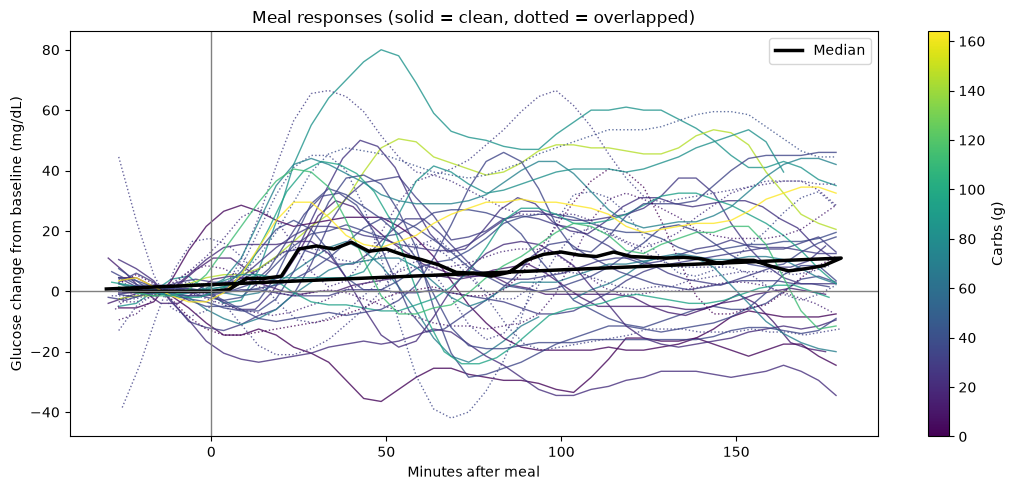

In [14]:
def aligned_curve(t, baseline, before=30, after=RESPONSE_WINDOW_MIN):
    w = grid[t - pd.Timedelta(minutes=before): t + pd.Timedelta(minutes=after)]
    return (w.index - t).total_seconds() / 60, w.values - baseline

fig, ax = plt.subplots(figsize=(11, 5))
cmap = plt.get_cmap("viridis")
cmax = max(mr["carbs"].max(), 1)
curves = []
for _, r in mr[mr["valid"]].iterrows():
    x, y = aligned_curve(r["time"], r["baseline"])
    ax.plot(x, y, color=cmap(r["carbs"] / cmax if pd.notna(r["carbs"]) else 0),
            lw=1, alpha=0.8, ls="-" if r["clean"] else ":")
    curves.append(pd.Series(y, index=np.round(x / 5) * 5))

if curves:
    med = pd.concat(curves, axis=1).median(axis=1)
    ax.plot(med.index, med.values, color="black", lw=2.5, label="Median")

ax.axvline(0, color="gray", lw=1)
ax.axhline(0, color="gray", lw=1)
ax.set_xlabel("Minutes after meal")
ax.set_ylabel("Glucose change from baseline (mg/dL)")
ax.set_title("Meal responses (solid = clean, dotted = overlapped)")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, cmax))
plt.colorbar(sm, ax=ax, label="Carbs (g)")
ax.legend()
plt.tight_layout()
plt.show()

---
## Q4: How long until glucose returns to baseline?

**Recovery time** = minutes from the meal until glucose first comes back within `RECOVERY_TOL` (10 mg/dL) of the baseline after the peak, searched up to 4 hours. In people without diabetes this is typically around 2–3 hours, and faster recovery suggests more efficient glucose regulation. Meals that never recovered within 4 h (or were interrupted by another meal) show as `NaN`.

Recovered within 4 h: 25 of 38
Median recovery time (all):   74 min
Median recovery time (clean): 66 min


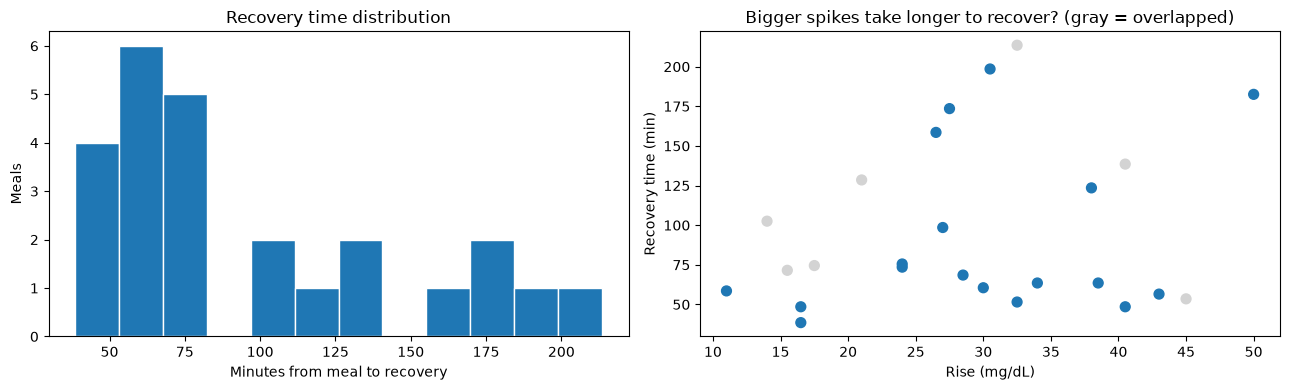

In [15]:
rec = mr[mr["valid"]]
print(f"Recovered within 4 h: {int(rec['recovery_min'].notna().sum())} of {len(rec)}")
print(f"Median recovery time (all):   {rec['recovery_min'].median():.0f} min")
print(f"Median recovery time (clean): {rec.loc[rec['clean'], 'recovery_min'].median():.0f} min")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(rec["recovery_min"].dropna(), bins=12, color="tab:blue", edgecolor="white")
axes[0].set_xlabel("Minutes from meal to recovery")
axes[0].set_ylabel("Meals")
axes[0].set_title("Recovery time distribution")

axes[1].scatter(rec["rise"], rec["recovery_min"], c=np.where(rec["clean"], "tab:blue", "lightgray"), s=50)
axes[1].set_xlabel("Rise (mg/dL)")
axes[1].set_ylabel("Recovery time (min)")
axes[1].set_title("Bigger spikes take longer to recover? (gray = overlapped)")
plt.tight_layout()
plt.show()

---
## Q5: Do more carbs or sugar mean bigger spikes?

We correlate carbs and sugar with the rise and the iAUC. Results are shown for all valid meals and for clean meals only, because an overlapping meal can inflate or cut short a response.

Spearman correlation is used: it only asks "does more carbs tend to mean a bigger rise?", without assuming a straight-line relationship.

In [16]:
def spearman(df, x, y, min_n=5):
    d = df[[x, y]].dropna()
    if len(d) < min_n:
        return pd.Series({"n": len(d), "rho": np.nan, "p": np.nan})
    rho, p = stats.spearmanr(d[x], d[y])
    return pd.Series({"n": len(d), "rho": rho, "p": p})

rows = {}
for subset, df in [("all valid", mr[mr["valid"]]), ("clean only", mr[mr["clean"]])]:
    for x in ["carbs", "sugar", "calories"]:
        for y in ["rise", "iAUC_2h"]:
            rows[(subset, x, y)] = spearman(df, x, y)
carb_corr = pd.DataFrame(rows).T.round(3)
carb_corr

n    rho      p
all valid  carbs    rise     38.0  0.378  0.019
                    iAUC_2h  38.0  0.459  0.004
           sugar    rise     38.0  0.301  0.066
                    iAUC_2h  38.0  0.362  0.026
           calories rise     38.0  0.078  0.642
                    iAUC_2h  38.0  0.237  0.151
clean only carbs    rise     28.0  0.487  0.009
                    iAUC_2h  28.0  0.497  0.007
           sugar    rise     28.0  0.526  0.004
                    iAUC_2h  28.0  0.519  0.005
           calories rise     28.0  0.085  0.669
                    iAUC_2h  28.0  0.170  0.388

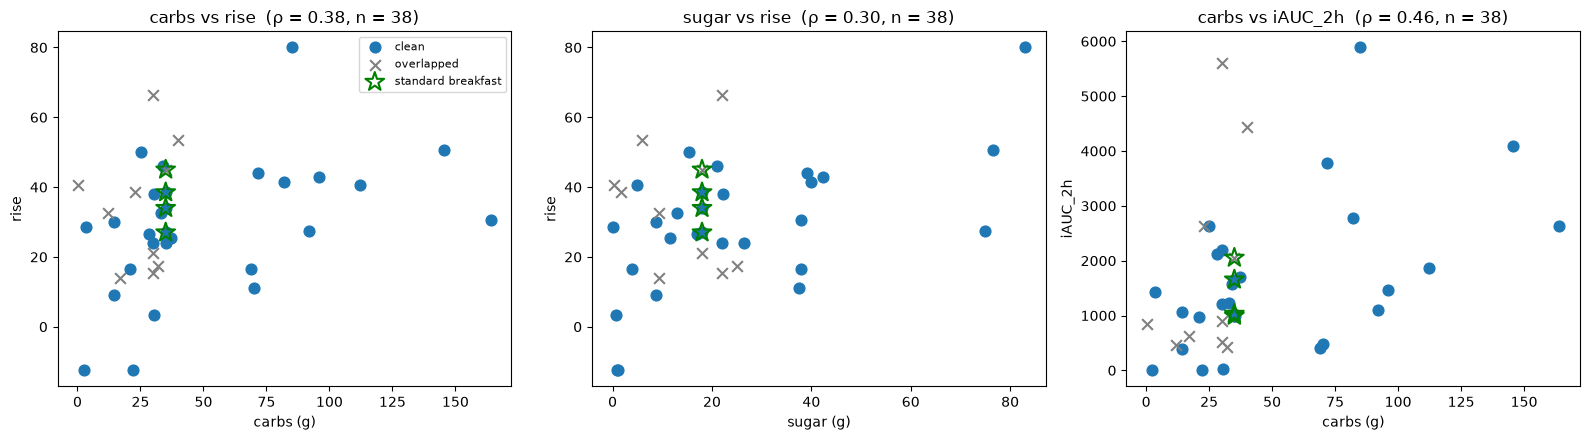

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
v = mr[mr["valid"]]
for ax, (x, y) in zip(axes, [("carbs", "rise"), ("sugar", "rise"), ("carbs", "iAUC_2h")]):
    for clean, mk, col in [(True, "o", "tab:blue"), (False, "x", "gray")]:
        s = v[v["clean"] == clean]
        ax.scatter(s[x], s[y], marker=mk, color=col, s=60, label="clean" if clean else "overlapped")
    st = v[v["standard"]]
    ax.scatter(st[x], st[y], marker="*", s=200, facecolor="none", edgecolor="green", lw=1.5, label="standard breakfast")
    r = spearman(v, x, y)
    ax.set_xlabel(f"{x} (g)")
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}  (ρ = {r['rho']:.2f}, n = {int(r['n'])})")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

---
## Q6: Do fiber, protein, or fat reduce the spike?

Protein, fat, and fiber slow down how fast carbs are absorbed, so they can make the same amount of carbs produce a smaller spike. To compare fairly, we use the **rise per 10 g of carbs** (only for meals with at least 10 g of carbs) and check whether it goes down as protein, fat, or fiber go up.

In this food log, fiber and fat are missing for most meals, so those results may be skipped or based on very few meals. Protein is usually available.

In [18]:
q6 = mr[mr["valid"] & mr["rise_per_10g_carb"].notna()]
print("Meals with ≥ 10 g carbs and a valid response:", len(q6))

q6_rows = {n: spearman(q6, n, "rise_per_10g_carb") for n in ["protein", "fat", "fiber"]}
q6_corr = pd.DataFrame(q6_rows).T.round(3)
q6_corr["direction"] = np.where(q6_corr["rho"] < 0, "more → smaller spike per carb",
                         np.where(q6_corr["rho"] > 0, "more → bigger spike per carb", "not enough data"))
q6_corr

Meals with ≥ 10 g carbs and a valid response: 35


,n,rho,p,direction
protein,35.0,-0.25,0.147,more → smaller spike per carb
fat,2.0,NaN,NaN,not enough data
fiber,2.0,NaN,NaN,not enough data


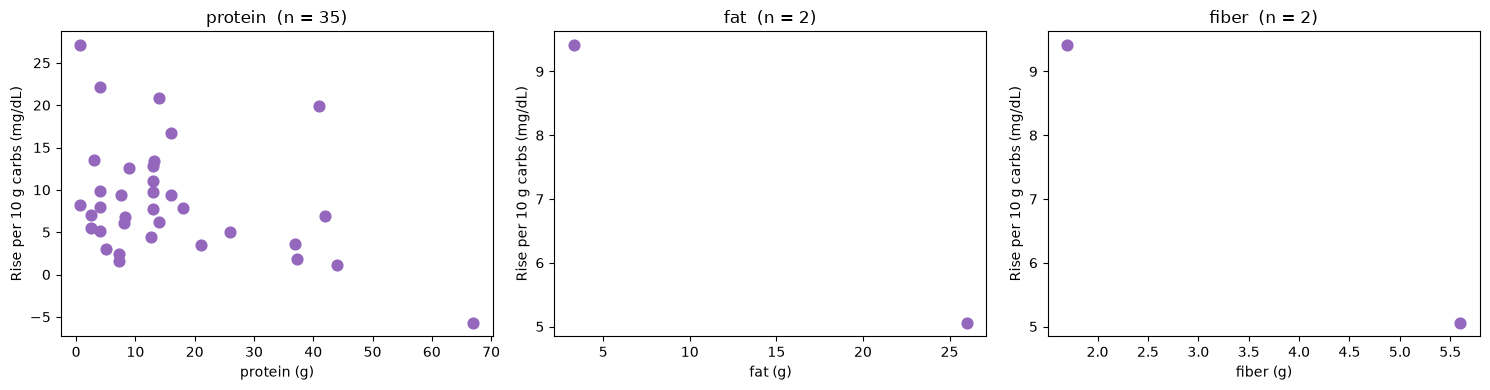

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, ["protein", "fat", "fiber"]):
    d = q6[[n, "rise_per_10g_carb", "foods"]].dropna()
    ax.scatter(d[n], d["rise_per_10g_carb"], s=60, color="tab:purple")
    ax.set_xlabel(f"{n} (g)")
    ax.set_ylabel("Rise per 10 g carbs (mg/dL)")
    ax.set_title(f"{n}  (n = {len(d)})")
    if len(d) == 0:
        ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
plt.tight_layout()
plt.show()

In [20]:
# Simple split: higher vs lower protein (median split)
if len(q6.dropna(subset=["protein"])) >= 6:
    med_p = q6["protein"].median()
    split = q6.assign(protein_group=np.where(q6["protein"] > med_p, f"> {med_p:.0f} g protein", f"≤ {med_p:.0f} g protein"))
    print(split.groupby("protein_group")[["carbs", "rise", "rise_per_10g_carb"]].median().round(1))
else:
    print("Not enough meals for a protein split")

                carbs  rise  rise_per_10g_carb
protein_group                                 
> 13 g protein   33.8  34.5                6.6
≤ 13 g protein   34.0  27.5                8.0


---
## Q7: Consistency of the standardized breakfast

The standard breakfast (Frosted Flakes with lactose-free milk, about 35 g carbs) is the closest thing to a controlled experiment in this dataset. If the participant's glucose regulation is consistent, the responses should look alike.

We compare the curves both as raw glucose and as change from baseline, and summarise consistency with the **CV of the rise** across days. Note any breakfast that was followed by another snack within 2 h (overlapped), because its curve will be distorted.

In [21]:
sb = mr[mr["standard"] & mr["valid"]].copy()
sb_cols = ["time", "foods", "carbs", "baseline", "peak", "rise", "time_to_peak_min",
           "iAUC_2h", "recovery_min", "nadir_after", "dip_below_baseline", "overlapped"]
print("Standard breakfasts with a valid response:", len(sb))
sb[sb_cols].assign(foods=lambda d: d["foods"].str[:30]).round(1)

Standard breakfasts with a valid response: 4


,time,foods,carbs,baseline,peak,rise,time_to_peak_min,iAUC_2h,recovery_min,nadir_after,dip_below_baseline,overlapped
2,2020-02-14 07:10:00,"Natrel Lactose Free 2 Percent,",35.0,95.0,122.0,27.0,68.5,1655.0,98.5,83.0,-12.0,False
11,2020-02-16 07:00:00,"Natrel Lactose Free 2 Percent,",35.0,88.0,133.0,45.0,28.5,2052.5,53.5,46.0,-42.0,True
20,2020-02-18 06:20:00,"Natrel Lactose Free 2 Percent,",35.0,102.5,141.0,38.5,43.5,1030.0,63.5,74.0,-28.5,False
33,2020-02-21 07:30:00,"Natrel Lactose Free 2 Percent,",35.0,108.0,142.0,34.0,33.5,995.0,63.5,89.0,-19.0,False


In [22]:
if len(sb) >= 2:
    cons = pd.DataFrame({
        "mean": sb[["baseline", "peak", "rise", "time_to_peak_min", "iAUC_2h"]].mean(),
        "SD": sb[["baseline", "peak", "rise", "time_to_peak_min", "iAUC_2h"]].std(),
    })
    cons["CV %"] = cons["SD"] / cons["mean"].abs() * 100
    print(cons.round(1))
    cv_rise = cons.loc["rise", "CV %"]
    print(f"\nCV of rise across standard breakfasts: {cv_rise:.0f}%",
          "→ fairly consistent" if cv_rise < 25 else "→ quite variable")
else:
    cv_rise = np.nan
    print("Fewer than 2 standard breakfasts, cannot assess consistency")

                    mean     SD  CV %
baseline            98.4    8.7   8.9
peak               134.5    9.3   6.9
rise                36.1    7.6  21.0
time_to_peak_min    43.5   17.8  40.9
iAUC_2h           1433.1  512.3  35.7

CV of rise across standard breakfasts: 21% → fairly consistent


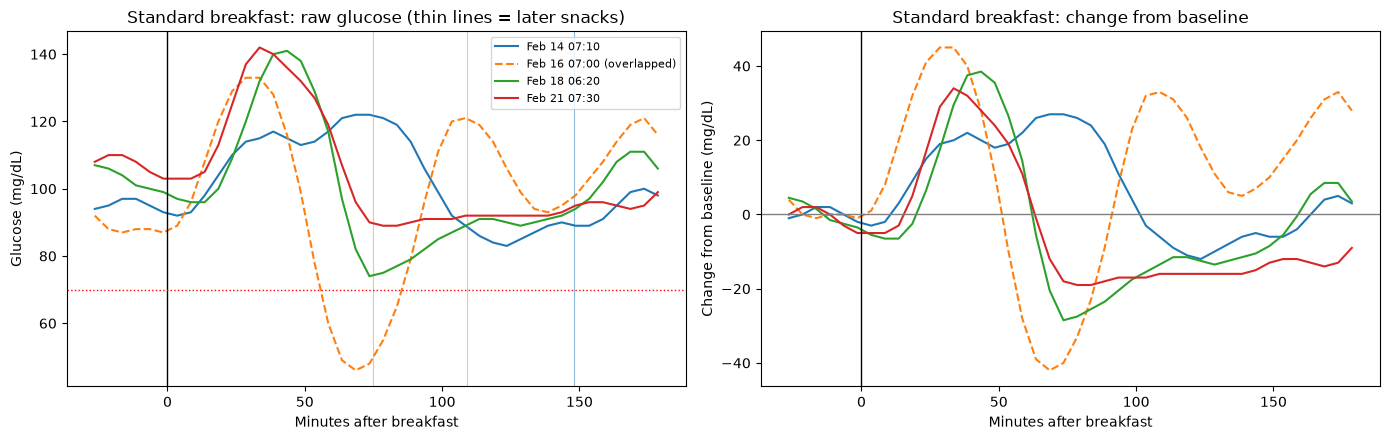

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
cmap = plt.get_cmap("tab10")
for i, (_, r) in enumerate(sb.iterrows()):
    w = grid[r["time"] - pd.Timedelta("30min"): r["time"] + pd.Timedelta(minutes=RESPONSE_WINDOW_MIN)]
    x = (w.index - r["time"]).total_seconds() / 60
    lab = f"{r['time']:%b %d %H:%M}{' (overlapped)' if r['overlapped'] else ''}"
    axes[0].plot(x, w.values, color=cmap(i), lw=1.5, label=lab, ls="--" if r["overlapped"] else "-")
    axes[1].plot(x, w.values - r["baseline"], color=cmap(i), lw=1.5, ls="--" if r["overlapped"] else "-")

    # mark any other meals eaten during the window
    later = meals[(meals["time"] > r["time"]) & (meals["time"] <= r["time"] + pd.Timedelta(minutes=RESPONSE_WINDOW_MIN))]
    for _, m in later.iterrows():
        axes[0].axvline((m["time"] - r["time"]).total_seconds() / 60, color=cmap(i), lw=0.8, alpha=0.5)

for ax in axes:
    ax.axvline(0, color="black", lw=1)
axes[0].axhline(70, color="red", ls=":", lw=1)
axes[0].set_ylabel("Glucose (mg/dL)")
axes[0].set_title("Standard breakfast: raw glucose (thin lines = later snacks)")
axes[0].legend(fontsize=8)
axes[1].axhline(0, color="gray", lw=1)
axes[1].set_ylabel("Change from baseline (mg/dL)")
axes[1].set_title("Standard breakfast: change from baseline")
for ax in axes:
    ax.set_xlabel("Minutes after breakfast")
plt.tight_layout()
plt.show()

---
## Q8: Breakfast vs lunch vs dinner

Meal type is set by time of day (breakfast 04:00–11:00, lunch 11:00–15:30, dinner 17:00–23:30, anything small or in between = snack).

Different meal types usually contain different amounts of carbs, so we compare both the raw **rise** and the **rise per 10 g carbs**. Some studies find the same food causes a bigger response later in the day, as insulin sensitivity tends to be higher in the morning, but this varies a lot between people.

In [24]:
order = ["breakfast", "lunch", "dinner", "snack"]
q8 = mr[mr["valid"]]
by_type = q8.groupby("type")[["carbs", "baseline", "rise", "rise_per_10g_carb", "time_to_peak_min",
                              "iAUC_2h", "recovery_min"]].median().reindex(order)
by_type.insert(0, "meals", q8.groupby("type").size().reindex(order))
by_type.round(1)

,meals,carbs,baseline,rise,rise_per_10g_carb,time_to_peak_min,iAUC_2h,recovery_min
type,,,,,,,,
breakfast,10,35.0,93.2,33.2,8.9,37.5,1215.6,63.5
lunch,12,30.0,94.5,27.0,6.5,56.5,1088.8,73.5
dinner,10,38.6,100.8,28.0,6.1,53.5,2170.6,118.5
snack,6,14.5,111.2,35.2,13.0,85.5,1140.0,123.5


Kruskal–Wallis test on rise across meal types: p = 0.770  (small samples, treat as a rough guide)


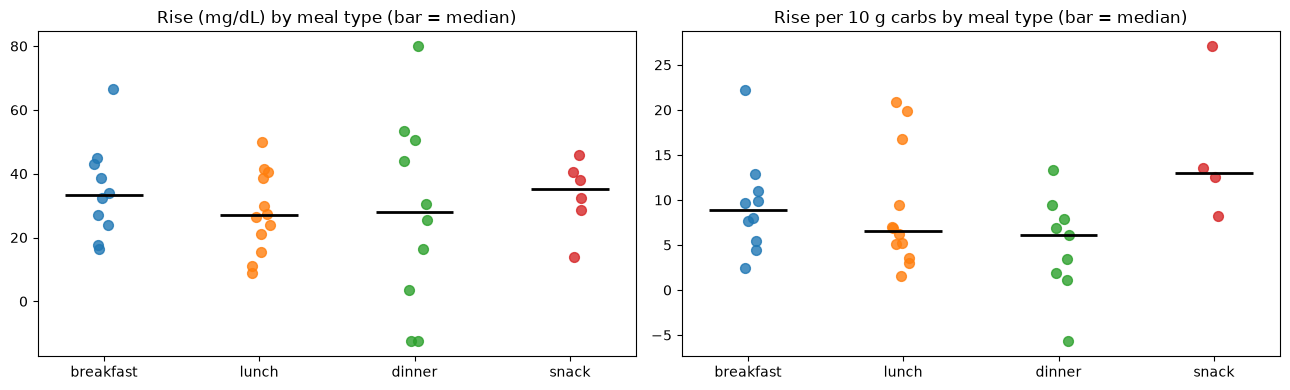

In [25]:
groups = [q8.loc[q8["type"] == t, "rise"].dropna() for t in order if (q8["type"] == t).sum() >= 2]
if len(groups) >= 2:
    h, p = stats.kruskal(*groups)
    print(f"Kruskal–Wallis test on rise across meal types: p = {p:.3f}  (small samples, treat as a rough guide)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, title in [(axes[0], "rise", "Rise (mg/dL)"), (axes[1], "rise_per_10g_carb", "Rise per 10 g carbs")]:
    for i, t in enumerate(order):
        vals = q8.loc[q8["type"] == t, col].dropna()
        ax.scatter(np.full(len(vals), i) + np.random.uniform(-0.08, 0.08, len(vals)), vals, s=50, alpha=0.8)
        if len(vals):
            ax.hlines(vals.median(), i - 0.25, i + 0.25, color="black", lw=2)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order)
    ax.set_title(f"{title} by meal type (bar = median)")
plt.tight_layout()
plt.show()

---
## Q9 (added): Dips below baseline after a spike

Sometimes glucose falls **below** its pre-meal level after a spike. This *reactive low* happens when the body releases more insulin than needed. Stage 1 found one on Feb 16 (down to about 46 mg/dL).

We flag meals where the lowest point in the 3 h after the meal is more than 10 mg/dL below baseline, or below 70 mg/dL.

In [26]:
q9 = mr[mr["valid"]].copy()
q9["reactive_dip"] = (q9["dip_below_baseline"] < -10) | (q9["nadir_after"] < 70)
print(f"Meals followed by a dip below baseline: {int(q9['reactive_dip'].sum())} of {len(q9)}")
q9.loc[q9["reactive_dip"], ["time", "type", "foods", "carbs", "sugar", "baseline", "peak",
                             "nadir_after", "dip_below_baseline", "liquid"]] \
    .assign(foods=lambda d: d["foods"].str[:35]).round(1)

Meals followed by a dip below baseline: 15 of 38


,time,type,foods,carbs,sugar,baseline,peak,nadir_after,dip_below_baseline,liquid
1,2020-02-13 20:30:00,dinner,"Chicken Leg, Asparagus",2.5,0.8,118.5,106.0,82.0,-36.5,False
2,2020-02-14 07:10:00,breakfast,"Natrel Lactose Free 2 Percent, Stan",35.0,18.0,95.0,122.0,83.0,-12.0,False
6,2020-02-15 07:30:00,breakfast,Spinach Smoothie,69.0,38.0,85.5,102.0,62.0,-23.5,True
8,2020-02-15 12:38:00,lunch,"Spinach Salad w/ blueberries, egg,",14.4,8.7,91.0,100.0,71.0,-20.0,False
11,2020-02-16 07:00:00,breakfast,"Natrel Lactose Free 2 Percent, Stan",35.0,18.0,88.0,133.0,46.0,-42.0,False
13,2020-02-16 08:49:00,breakfast,Hot Chocolate,32.0,25.0,103.5,121.0,84.0,-19.5,True
15,2020-02-16 21:10:00,snack,Chai Tea,3.4,0.0,113.5,142.0,89.0,-24.5,True
16,2020-02-17 06:42:00,breakfast,Maple Brown Sugar Oatmeal,33.0,13.0,91.5,124.0,78.0,-13.5,False
20,2020-02-18 06:20:00,breakfast,"Natrel Lactose Free 2 Percent, Stan",35.0,18.0,102.5,141.0,74.0,-28.5,False
23,2020-02-18 13:40:00,lunch,Kale and Fruit Smoothie,70.0,37.5,123.0,134.0,103.0,-20.0,True


In [27]:
d = q9[["rise", "dip_below_baseline"]].dropna()
if len(d) >= 5:
    rho, p = stats.spearmanr(d["rise"], d["dip_below_baseline"])
    print(f"Bigger rise → deeper dip?  Spearman rho = {rho:.2f} (p = {p:.3f})")
    print("A negative rho means bigger spikes tend to be followed by deeper dips.")

Bigger rise → deeper dip?  Spearman rho = 0.51 (p = 0.001)
A negative rho means bigger spikes tend to be followed by deeper dips.


---
## Q10 (added): Does the starting level affect the spike?

If glucose is already high before eating, there may be less room to rise, or the body may already be releasing insulin. We check whether the **baseline** relates to the **rise** and the **peak**.

baseline vs rise              : rho = -0.42  (p = 0.008, n = 38)
baseline vs peak              : rho = +0.44  (p = 0.006, n = 38)
baseline vs rise_per_10g_carb : rho = -0.25  (p = 0.143, n = 35)


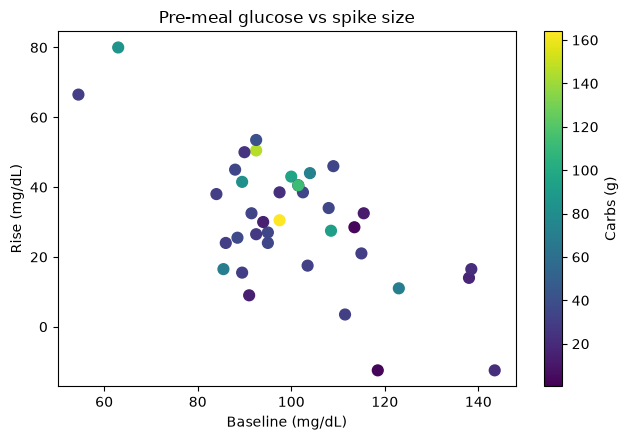

In [28]:
q10 = mr[mr["valid"]]
for y in ["rise", "peak", "rise_per_10g_carb"]:
    r = spearman(q10, "baseline", y)
    print(f"baseline vs {y:18s}: rho = {r['rho']:+.2f}  (p = {r['p']:.3f}, n = {int(r['n'])})")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(q10["baseline"], q10["rise"], c=q10["carbs"], cmap="viridis", s=60)
plt.colorbar(sc, ax=ax, label="Carbs (g)")
ax.set_xlabel("Baseline (mg/dL)")
ax.set_ylabel("Rise (mg/dL)")
ax.set_title("Pre-meal glucose vs spike size")
plt.tight_layout()
plt.show()

---
## Q11 (added): Liquid vs solid meals

This participant drinks a lot of smoothies, often with 70–90 g of carbs. Liquid carbs are usually absorbed faster than the same carbs in solid food, which tends to give a quicker and higher spike.

A meal counts as liquid if at least half its carbs came from drinks.

In [29]:
q11 = mr[mr["valid"]].copy()
q11["form"] = np.where(q11["liquid"], "liquid", "solid")
liq = q11.groupby("form")[["carbs", "sugar", "rise", "rise_per_10g_carb", "time_to_peak_min", "iAUC_2h"]].median()
liq.insert(0, "meals", q11.groupby("form").size())
print(liq.round(1))

a = q11.loc[q11["form"] == "liquid", "rise_per_10g_carb"].dropna()
b = q11.loc[q11["form"] == "solid", "rise_per_10g_carb"].dropna()
if len(a) >= 2 and len(b) >= 2:
    print(f"\nRise per 10 g carbs, liquid vs solid: Mann–Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f}")

        meals  carbs  sugar  rise  rise_per_10g_carb  time_to_peak_min  \
form                                                                     
liquid     11   71.8   39.2  28.5                4.8              48.5   
solid      27   30.0   13.0  30.5                9.4              56.5   

        iAUC_2h  
form             
liquid   1433.8  
solid    1210.0  

Rise per 10 g carbs, liquid vs solid: Mann–Whitney p = 0.005


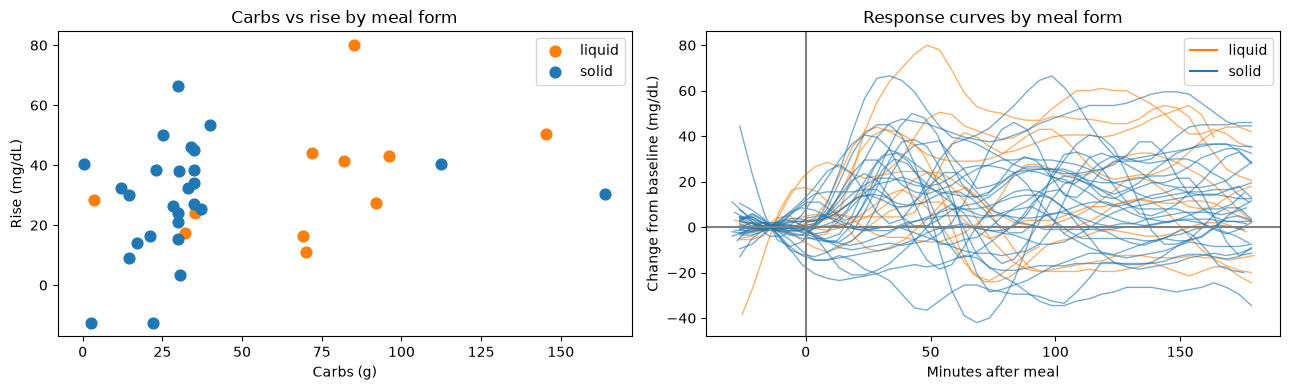

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for form, col in [("liquid", "tab:orange"), ("solid", "tab:blue")]:
    s = q11[q11["form"] == form]
    axes[0].scatter(s["carbs"], s["rise"], color=col, s=60, label=form)
    for _, r in s.iterrows():
        x, y = aligned_curve(r["time"], r["baseline"])
        axes[1].plot(x, y, color=col, alpha=0.6, lw=1)
axes[0].set_xlabel("Carbs (g)")
axes[0].set_ylabel("Rise (mg/dL)")
axes[0].set_title("Carbs vs rise by meal form")
axes[0].legend()
axes[1].plot([], [], color="tab:orange", label="liquid")
axes[1].plot([], [], color="tab:blue", label="solid")
axes[1].axvline(0, color="gray")
axes[1].axhline(0, color="gray")
axes[1].set_xlabel("Minutes after meal")
axes[1].set_ylabel("Change from baseline (mg/dL)")
axes[1].set_title("Response curves by meal form")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## Q12 (added): Biggest responses

The meals with the largest rise and the largest iAUC. These are the participant's most "glucose-heavy" foods in this dataset. The overlap flag matters here: an overlapped meal's response may partly belong to the next meal.

In [31]:
top_cols = ["time", "type", "foods", "carbs", "sugar", "rise", "iAUC_2h", "time_to_peak_min", "liquid", "overlapped"]
v = mr[mr["valid"]]
print("Top 5 by rise:")
v.nlargest(5, "rise")[top_cols].assign(foods=lambda d: d["foods"].str[:40]).round(1)

Top 5 by rise:


,time,type,foods,carbs,sugar,rise,iAUC_2h,time_to_peak_min,liquid,overlapped
0,2020-02-13 18:00:00,dinner,Berry Smoothie,85.0,83.0,80.0,5887.5,48.5,True,False
12,2020-02-16 08:15:00,breakfast,Breakfast Trail Mix,30.0,22.0,66.5,5600.0,33.5,False,True
18,2020-02-17 21:00:00,dinner,"Kale Salad, Pizza",40.0,5.9,53.5,4440.0,113.5,False,True
5,2020-02-14 19:30:00,dinner,"Acai Smoothie, (Trader Joe's) Mac and Ch",145.5,76.6,50.5,4090.0,53.5,True,False
14,2020-02-16 11:56:00,lunch,"Salty Sweet Popcorn, Bourbon Chicken, Sh",25.1,15.4,50.0,2635.0,42.5,False,False


In [32]:
print("Top 5 by iAUC (height × duration):")
v.nlargest(5, "iAUC_2h")[top_cols].assign(foods=lambda d: d["foods"].str[:40]).round(1)

Top 5 by iAUC (height × duration):


,time,type,foods,carbs,sugar,rise,iAUC_2h,time_to_peak_min,liquid,overlapped
0,2020-02-13 18:00:00,dinner,Berry Smoothie,85.0,83.0,80.0,5887.5,48.5,True,False
12,2020-02-16 08:15:00,breakfast,Breakfast Trail Mix,30.0,22.0,66.5,5600.0,33.5,False,True
18,2020-02-17 21:00:00,dinner,"Kale Salad, Pizza",40.0,5.9,53.5,4440.0,113.5,False,True
5,2020-02-14 19:30:00,dinner,"Acai Smoothie, (Trader Joe's) Mac and Ch",145.5,76.6,50.5,4090.0,53.5,True,False
32,2020-02-20 20:15:00,dinner,"Salad, Green Smoothie",71.8,39.2,44.0,3787.5,28.5,True,False


In [33]:
print("Smallest rises among meals with ≥ 20 g carbs (well tolerated):")
v[v["carbs"] >= 20].nsmallest(5, "rise")[top_cols].assign(foods=lambda d: d["foods"].str[:40]).round(1)

Smallest rises among meals with ≥ 20 g carbs (well tolerated):


,time,type,foods,carbs,sugar,rise,iAUC_2h,time_to_peak_min,liquid,overlapped
28,2020-02-19 20:00:00,dinner,Chicken and Rice,22.0,1.0,-12.5,0.0,NaN,False,False
24,2020-02-18 22:00:00,dinner,Ranch Wings,30.4,0.6,3.5,23.8,NaN,False,False
23,2020-02-18 13:40:00,lunch,Kale and Fruit Smoothie,70.0,37.5,11.0,487.5,48.5,True,False
7,2020-02-15 11:02:00,lunch,Breakfast Trail Mix,30.0,22.0,15.5,905.0,56.5,False,True
6,2020-02-15 07:30:00,breakfast,Spinach Smoothie,69.0,38.0,16.5,398.8,38.5,True,False


---
## Summary

All Stage 6 answers in one table. The per-meal responses and the spike list are saved for later stages (e.g. checking HR around meals).

In [34]:
r_carb = spearman(mr[mr["valid"]], "carbs", "rise")
std_rise = sb["rise"].mean() if len(sb) else np.nan

summary = pd.Series({
    f"Absolute spikes (≥ {SPIKE_THR})": len(abs_spikes),
    "Relative spikes": len(peaks),
    "Spikes linked to a meal": f"{int(peaks['meal_linked'].sum())} of {len(peaks)}",
    "Spikes with no meal logged": int((~peaks["meal_linked"]).sum()),
    "Meals analysed (valid)": int(mr["valid"].sum()),
    "Clean meals (no overlap)": int(mr["clean"].sum()),
    "Median rise (mg/dL)": round(mr.loc[mr["valid"], "rise"].median(), 1),
    "Median time to peak (min)": round(mr.loc[mr["valid"], "time_to_peak_min"].median(), 0),
    "Median recovery (min)": round(mr.loc[mr["valid"], "recovery_min"].median(), 0),
    "Carbs vs rise (Spearman rho)": round(r_carb["rho"], 2),
    "Standard breakfast mean rise (mg/dL)": round(std_rise, 1),
    "Standard breakfast CV of rise (%)": round(cv_rise, 1),
    "Meals followed by a reactive dip": int(q9["reactive_dip"].sum()),
    "Median rise per 10 g carbs, liquid": round(liq.loc["liquid", "rise_per_10g_carb"], 1) if "liquid" in liq.index else np.nan,
    "Median rise per 10 g carbs, solid": round(liq.loc["solid", "rise_per_10g_carb"], 1) if "solid" in liq.index else np.nan,
}, name=PID)
summary.to_frame()

,001
Absolute spikes (≥ 140),22
Relative spikes,44
Spikes linked to a meal,31 of 44
Spikes with no meal logged,13
Meals analysed (valid),38
Clean meals (no overlap),28
Median rise (mg/dL),30.2
Median time to peak (min),54.0
Median recovery (min),74.0
Carbs vs rise (Spearman rho),0.38


In [35]:
summary.to_frame().T.rename_axis("participant").to_csv(f"../clean_data/stage6_summary_{PID}.csv")
mr.round(2).to_csv(f"../clean_data/stage6_meal_responses_{PID}.csv", index=False)
peaks.round(2).to_csv(f"../clean_data/stage6_spikes_{PID}.csv", index=False)
print(f"Saved stage6_summary_{PID}.csv, stage6_meal_responses_{PID}.csv, stage6_spikes_{PID}.csv")

Saved stage6_summary_001.csv, stage6_meal_responses_001.csv, stage6_spikes_001.csv
